# Исследование объявлений о продаже квартир

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Первичное знакомство (разделитель - t)
df = pd.read_csv("/content/real_estate_data.csv", sep="\t")
df.info()
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  object 
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  object 
 15  airports_nearest   

array([[<Axes: title={'center': 'total_images'}>,
        <Axes: title={'center': 'last_price'}>,
        <Axes: title={'center': 'total_area'}>,
        <Axes: title={'center': 'rooms'}>],
       [<Axes: title={'center': 'ceiling_height'}>,
        <Axes: title={'center': 'floors_total'}>,
        <Axes: title={'center': 'living_area'}>,
        <Axes: title={'center': 'floor'}>],
       [<Axes: title={'center': 'kitchen_area'}>,
        <Axes: title={'center': 'balcony'}>,
        <Axes: title={'center': 'airports_nearest'}>,
        <Axes: title={'center': 'cityCenters_nearest'}>],
       [<Axes: title={'center': 'parks_around3000'}>,
        <Axes: title={'center': 'parks_nearest'}>,
        <Axes: title={'center': 'ponds_around3000'}>,
        <Axes: title={'center': 'ponds_nearest'}>],
       [<Axes: title={'center': 'days_exposition'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

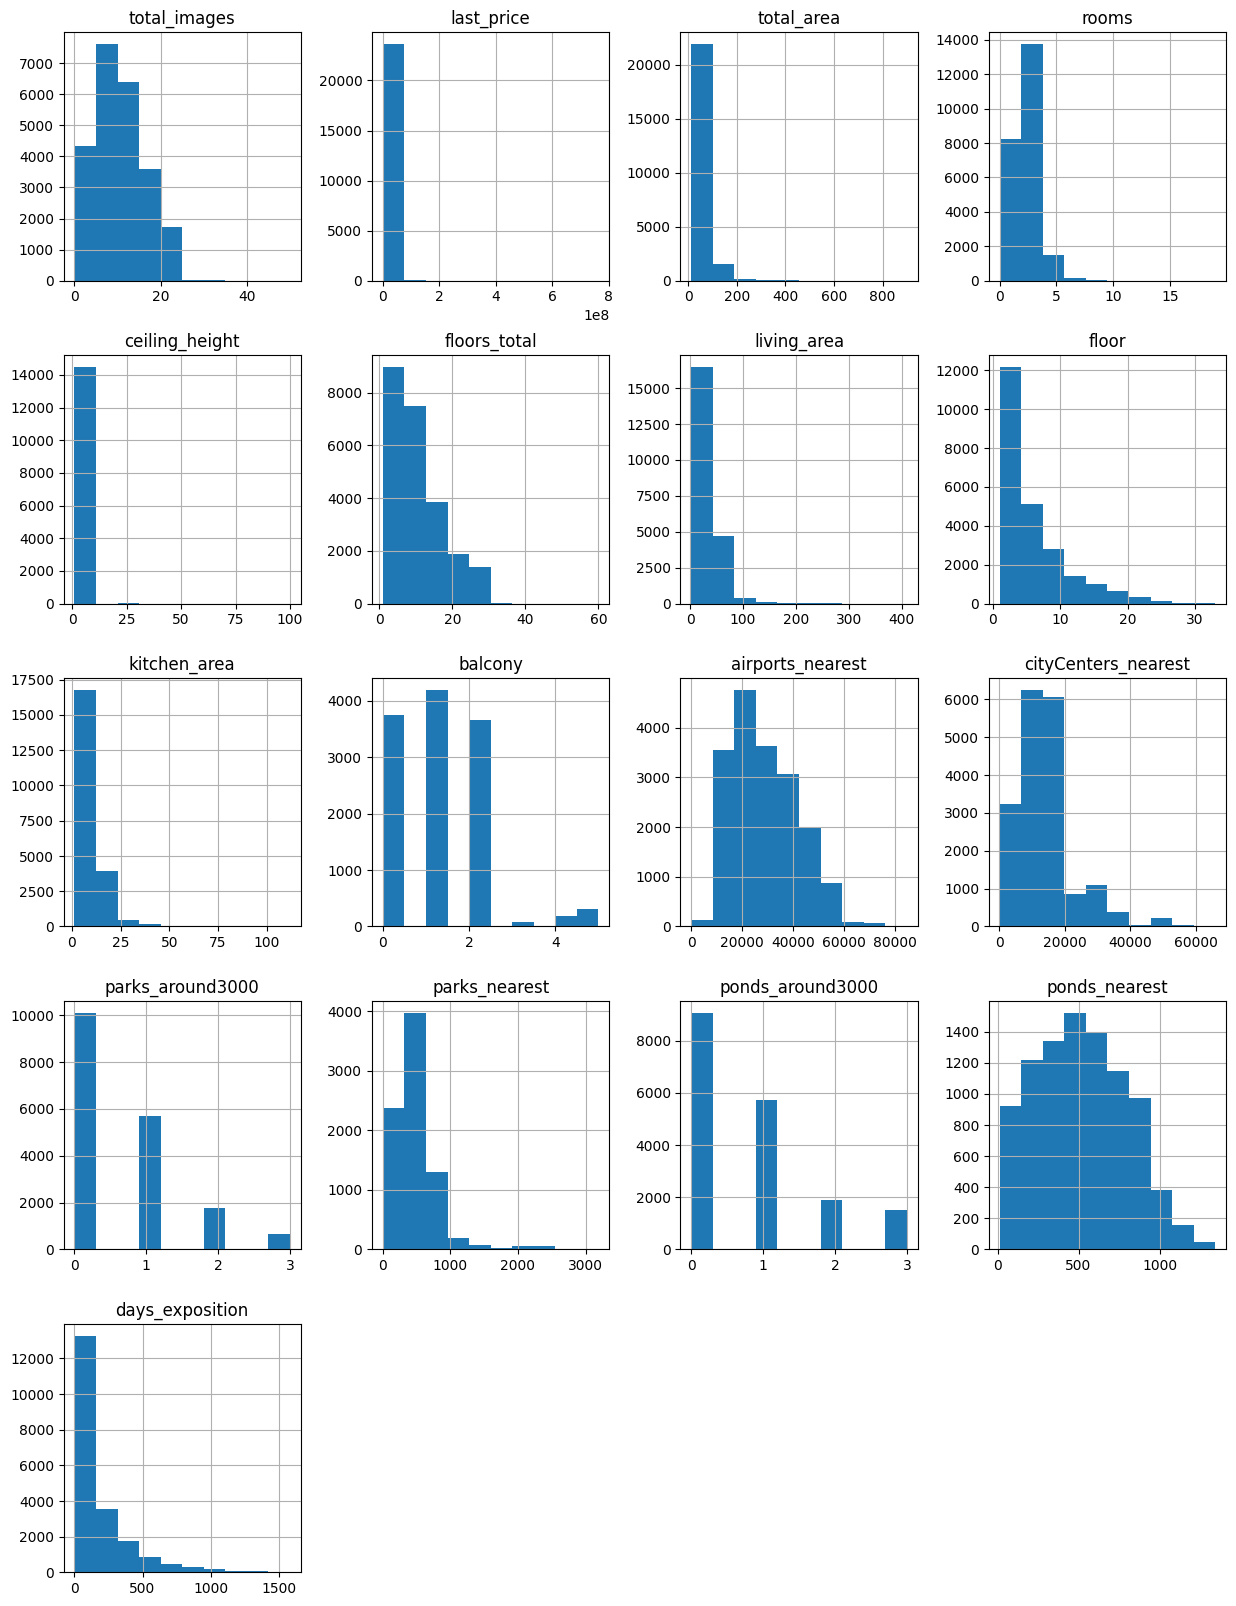

In [28]:
df.hist(figsize=(15, 20))

In [29]:
df.describe()

,total_images,last_price,total_area,rooms,ceiling_height,floors_total,living_area,floor,kitchen_area,balcony,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
count,23699.000000,2.369900e+04,23699.000000,23699.000000,14504.000000,23613.000000,21796.000000,23699.000000,21421.000000,12180.000000,18157.000000,18180.000000,18181.000000,8079.000000,18181.000000,9110.000000,20518.000000
mean,9.858475,6.541549e+06,60.348651,2.070636,2.771499,10.673824,34.457852,5.892358,10.569807,1.150082,28793.672193,14191.277833,0.611408,490.804555,0.770255,517.980900,180.888634
std,5.682529,1.088701e+07,35.654083,1.078405,1.261056,6.597173,22.030445,4.885249,5.905438,1.071300,12630.880622,8608.386210,0.802074,342.317995,0.938346,277.720643,219.727988
min,0.000000,1.219000e+04,12.000000,0.000000,1.000000,1.000000,2.000000,1.000000,1.300000,0.000000,0.000000,181.000000,0.000000,1.000000,0.000000,13.000000,1.000000
25%,6.000000,3.400000e+06,40.000000,1.000000,2.520000,5.000000,18.600000,2.000000,7.000000,0.000000,18585.000000,9238.000000,0.000000,288.000000,0.000000,294.000000,45.000000
50%,9.000000,4.650000e+06,52.000000,2.000000,2.650000,9.000000,30.000000,4.000000,9.100000,1.000000,26726.000000,13098.500000,0.000000,455.000000,1.000000,502.000000,95.000000
75%,14.000000,6.800000e+06,69.900000,3.000000,2.800000,16.000000,42.300000,8.000000,12.000000,2.000000,37273.000000,16293.000000,1.000000,612.000000,1.000000,729.000000,232.000000
max,50.000000,7.630000e+08,900.000000,19.000000,100.000000,60.000000,409.700000,33.000000,112.000000,5.000000,84869.000000,65968.000000,3.000000,3190.000000,3.000000,1344.000000,1580.000000


Видим немало пропусков и аномалий в данных.

- last_price (цена объекта): из-за нескольких элитных дворцов квартиры массового сегмента слились в один столбец. Если цель - анализ массового сегмента, то элитную недвижимость необходимо исключить.
- total_area, living_area, kitchen_area (площади): на гистограмме шкалы уходят за рамки стандартного метража квартир, что свидетельствует о наличии единичных пентхаусов или (возможно) коммерческой недвижимости, которые скорее трактуются как аномалии в нашем случае.
- ceiling_height (высота потолков): 100 метров - явная аномалия, похожая на опечатку
- rooms (количество комнат): 19 комнат - редкость, можно предположить, что это многокомнатная коммуналка в старом фонде. Основной пик приходится на 1, 2 и 3 комнаты.
- floors_total и floor (этажность): выбиваются 60 этажей - в Санкт-Петербурге и Лен.области отсутствуют небоскребы. График текущего этажа (floor) выглядит логичнее, но тоже имеет длинный «хвост» вправо.
- days_exposition (время продажи): видим на графике 1500 дней (более 4 лет), а основной массив квартир продается за 100 дней. Обычно сильно долго объявления не висят, но т.к. в тот период была возможность бесплатно размещать предложение, то могли забыть снять с продажи объявление.
- cityCenters_nearest и airports_nearest (расстояния): расстояния до центра города на графике можно разделить на две части: небольшое количество объектов находится достаточно близко к центру, а другая часть - в районе 10–20 км, что отражает расположение крупных спальных районов.
- parks_around3000 и ponds_around3000 (парки/пруды вокруг): данные распределены дискретно - 0, 1, 2, 3 объекта. У большинства объявлений в радиусе 3 км парков и прудов нет (высокий столбец на 0), либо их количество измеряется единицами. У parks_around3000 столбец нуля достаточно большой.
- parks_nearest и ponds_nearest (расстояние до парка/пруда): график парков обрывается в районе 1000 метров (дальше 1 км не считали). Пропуски огромные, но само распределение выглядит естественным: если парк рядом есть, то до него обычно от 200 до 600 метров.

## Работа с пропусками

In [30]:
print("Пропуски до обработки:\n", df.isna().sum())

Пропуски до обработки:
 total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height           9195
floors_total               86
living_area              1903
floor                       0
is_apartment            20924
studio                      0
open_plan                   0
kitchen_area             2278
balcony                 11519
locality_name              49
airports_nearest         5542
cityCenters_nearest      5519
parks_around3000         5518
parks_nearest           15620
ponds_around3000         5518
ponds_nearest           14589
days_exposition          3181
dtype: int64


### Причины появления пропусков

Возможные причины пропусков: **человеческий фактор** (опечатки или нежелание пользователей заполнять данные) и **технические сбои** (ошибки выгрузки или геосервисов/других систем).
* **`balcony` (балконы):** если балкона в квартире нет, продавцы просто оставляют поле пустым. Такие пропуски корректно заменить на `0`.
* **`is_apartment` (статус апартаментов):** владельцы обычных квартир могут пропустить этот пункт, так как по умолчанию считают своё жильё стандартным. Пропуски можно заменить на `False`.
* **`ceiling_height` (высота потолков):** при продаже собственники могут не указать точную высоту потолков в квартире, возможны опечатки.
* **`living_area` и `kitchen_area` (жилая площадь и площадь кухни):** владельцы могут не помнить точные параметры из паспорта объекта или указывать только общую площадь.
* **`floors_total` (всего этажей в доме):** пользователь мог забыть указать/пропустить этажность дома.

* **`airports_nearest`, `cityCenters_nearest`, `parks_nearest`, `ponds_nearest`:** параметры рассчитываются автоматически на основе картографических данных по адресу дома. Пропуски возникают, если:
  1. Система не смогла распознать адрес (например, из-за опечатки в названии населенного пункта).
  2. Объект находится слишком далеко от Санкт-Петербурга (например, в удаленной деревне Ленинградской области), где нет аэропортов, а парки и водоемы не внесены в базу данных.
* **`parks_around3000` и `ponds_around3000`:** пропуск в количестве водоемов/парков в радиусе 3 км означает, что сервис не нашел их в указанном радиусе. Можно заменить на `0`.

* **`days_exposition` (количество дней размещения объявления):** пропуски могут означать, что на момент выгрузки датасета квартира еще не была продана. Скорее всего есть аномальное значение

In [31]:
# Обработаем пропуски
# Балконы заменяем на 0
df["balcony"] = df["balcony"].fillna(0)

# Апартаменты: если не указано, заменяем на False
df["is_apartment"] = df["is_apartment"].fillna(False)

# Парки и пруды в радиусе 3 км:если отсутствуют, заменяем на 0
df["parks_around3000"] = df["parks_around3000"].fillna(0)
df["ponds_around3000"] = df["ponds_around3000"].fillna(0)

print("\nПропуски после обработки:\n", df.isna().sum())


Пропуски после обработки:
 total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height           9195
floors_total               86
living_area              1903
floor                       0
is_apartment                0
studio                      0
open_plan                   0
kitchen_area             2278
balcony                     0
locality_name              49
airports_nearest         5542
cityCenters_nearest      5519
parks_around3000            0
parks_nearest           15620
ponds_around3000            0
ponds_nearest           14589
days_exposition          3181
dtype: int64


/tmp/ipykernel_2464/255049783.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["is_apartment"] = df["is_apartment"].fillna(False)


- ceiling_height (высота потолков): можно заполнить медианой, но лучше в зависимости от типа дома или локации (однако, у нас отсутствуют такие данные, а по косвенным признакам трудно типизировать)
- floors_total (всего этажей): пропусков очень мало - менее 1% данных, можно удалить строки
- living_area и kitchen_area (площади): их пропуск критичен для анализа. Фиксированным числом заполнять нельзя. Лучший способ — найти медианную долю жилой площади и кухни от общей площади (total_area) и рассчитать пропуски на её основе.
- locality_name (название населенного пункта): Пропусков всего 49. Без знания локации мы не сможем оценить стоимость и удаленность от центра. Эти строки стоит удалить.
- airports_nearest, cityCenters_nearest, parks_nearest, ponds_nearest: эти пропуски заполнить не получится. Если объект находится в области, то понятие центра города для него неприменимо. Также трудно вычислить расположение аэропорта поблизости.

In [32]:
# Удалим строки с пропусками в floors_total и locality_name (их критически мало)
df = df.dropna(subset=["floors_total", "locality_name"])

# Заполним ceiling_height медианой в зависимости от этажности дома
df["ceiling_height"] = df["ceiling_height"].fillna(
    df.groupby("floors_total")["ceiling_height"].transform("median")
)
# единичные пропуски заполним общей медианой
df["ceiling_height"] = df["ceiling_height"].fillna(
    df["ceiling_height"].median()
)

# Заполним площади по пропорции от общей площади
living_ratio = (df["living_area"] / df["total_area"]).median()
df["living_area"] = df["living_area"].fillna(df["total_area"] * living_ratio)

# Находим общую медианную долю площади кухни
kitchen_ratio = (df["kitchen_area"] / df["total_area"]).median()
df["kitchen_area"] = df["kitchen_area"].fillna(
    df["total_area"] * kitchen_ratio
)

print(df.isna().sum())

total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height              0
floors_total                0
living_area                 0
floor                       0
is_apartment                0
studio                      0
open_plan                   0
kitchen_area                0
balcony                     0
locality_name               0
airports_nearest         5524
cityCenters_nearest      5501
parks_around3000            0
parks_nearest           15535
ponds_around3000            0
ponds_nearest           14529
days_exposition          3171
dtype: int64


## Работа с типами данных

In [33]:
# Переведем дату публикации из object в datetime
df["first_day_exposition"] = pd.to_datetime(
    df["first_day_exposition"], format="%Y-%m-%dT%H:%M:%S"
)

# Перевод в целые числа
int_columns = [
    "last_price",  # цена
    "floors_total",  # общее количество этажей
    "balcony",  # количество балконов
    "parks_around3000",  # количество парков
    "ponds_around3000",  # количество прудов
]

for col in int_columns:
    df[col] = df[col].astype("int64")

# is_apartment переведем из object в булев тип
df["is_apartment"] = df["is_apartment"].astype("bool")

print(df.dtypes)

total_images                     int64
last_price                       int64
total_area                     float64
first_day_exposition    datetime64[ns]
rooms                            int64
ceiling_height                 float64
floors_total                     int64
living_area                    float64
floor                            int64
is_apartment                      bool
studio                            bool
open_plan                         bool
kitchen_area                   float64
balcony                          int64
locality_name                   object
airports_nearest               float64
cityCenters_nearest            float64
parks_around3000                 int64
parks_nearest                  float64
ponds_around3000                 int64
ponds_nearest                  float64
days_exposition                float64
dtype: object


Приведение типов данных к корректным форматам необходимо для корректной работы математических вычислений и удобства дальнейшего анализа.

1. **`first_day_exposition` (из `object` в `datetime64`):** перевод в формат `datetime` позволит извлекать отдельные элементы времени: день недели, месяц и год публикации объявления для исследования сезонности продаж

2. **`last_price` (из `float64` в `int64`):**
цены на недвижимость исчисляются миллионами рублей, перевод в целые числа делает графики и таблицы более читаемыми

3. **`floors_total`, `balcony`, `parks_around3000`, `ponds_around3000` (из `float64` в `int64`):** количество этажей в доме, балконов в квартире, парков или прудов в округе — это дискретные величины. Изначально они были `float64` из-за наличия пропусков `NaN`. После заполнения или удаления пропусков логично привести их к целочисленному типу

4. **`is_apartment` (из `object` в `bool`):** столбец отвечает на бинарный вопрос: «Является ли объект апартаментами?». Хранить такие данные в виде строк или объектов неэффективно, приведение к логическому типу ускоряет вычисления и занимает меньше памяти

Столбцы days_exposition, living_area, ceiling_height оставим в формате float64, так как в них либо остались пропуски NaN, которые технически не могут быть в обычном int, либо сами значения содержат дробные части

In [34]:
print("Уникальных названий до очистки:", df["locality_name"].nunique())
print(df["locality_name"].unique()[:60])

Уникальных названий до очистки: 364
['Санкт-Петербург' 'посёлок Шушары' 'городской посёлок Янино-1'
 'посёлок Парголово' 'посёлок Мурино' 'Ломоносов' 'Сертолово' 'Петергоф'
 'Пушкин' 'деревня Кудрово' 'Коммунар' 'Колпино'
 'поселок городского типа Красный Бор' 'Гатчина' 'поселок Мурино'
 'деревня Фёдоровское' 'Выборг' 'Кронштадт' 'Кировск'
 'деревня Новое Девяткино' 'посёлок Металлострой'
 'посёлок городского типа Лебяжье' 'посёлок городского типа Сиверский'
 'поселок Молодцово' 'поселок городского типа Кузьмоловский'
 'садовое товарищество Новая Ропша' 'Павловск' 'деревня Пикколово'
 'Всеволожск' 'Волхов' 'Кингисепп' 'Приозерск' 'Сестрорецк'
 'деревня Куттузи' 'посёлок Аннино' 'поселок городского типа Ефимовский'
 'посёлок Плодовое' 'деревня Заклинье' 'поселок Торковичи'
 'поселок Первомайское' 'Красное Село' 'посёлок Понтонный' 'Сясьстрой'
 'деревня Старая' 'деревня Лесколово' 'посёлок Новый Свет' 'Сланцы'
 'село Путилово' 'Ивангород' 'Мурино' 'Шлиссельбург' 'Никольское'
 'Зеленогорс

In [35]:
# Замена ё на е, приведение к нижнему регистру
df["locality_name_clean"] = (df["locality_name"].str.lower().str.replace("ё", "е"))
df["locality_name"] = df["locality_name_clean"]
df = df.drop(columns=["locality_name_clean"])
print("Уникальных названий осталось:", df["locality_name"].nunique())
print(sorted(df["locality_name"].unique()))

Уникальных названий осталось: 330
['бокситогорск', 'волосово', 'волхов', 'всеволожск', 'выборг', 'высоцк', 'гатчина', 'городской поселок большая ижора', 'городской поселок будогощь', 'городской поселок виллози', 'городской поселок лесогорский', 'городской поселок мга', 'городской поселок назия', 'городской поселок новоселье', 'городской поселок павлово', 'городской поселок рощино', 'городской поселок свирьстрой', 'городской поселок советский', 'городской поселок федоровское', 'городской поселок янино-1', 'деревня агалатово', 'деревня аро', 'деревня батово', 'деревня бегуницы', 'деревня белогорка', 'деревня большая вруда', 'деревня большая пустомержа', 'деревня большие колпаны', 'деревня большое рейзино', 'деревня большой сабск', 'деревня бор', 'деревня борисова грива', 'деревня ваганово', 'деревня вартемяги', 'деревня вахнова кара', 'деревня выскатка', 'деревня гарболово', 'деревня глинка', 'деревня горбунки', 'деревня гостилицы', 'деревня заклинье', 'деревня заневка', 'деревня зимитиц

Обнаружили дубликаты следующего вида: 'городской поселок павлово', 'поселок городского типа павлово', 'село павлово' записаны в разных вариантах. Есть и другие примеры дубликатов в данных. Необходимо от них избавиться

In [36]:
# Функция для очистки названий от категорий
def remove_locality_types(text):
    if pd.isna(text):
        return text

    # Список слов, которые нужно удалить
    words_to_remove = [
        "поселок городского типа",
        "садоводческое некоммерческое товарищество",
        "городской поселок",
        "коттеджный поселок",
        "поселок при железнодорожной станции",
        "садовое товарищество",
        "станции",
        "деревня",
        "поселок",
        "село",
        "садовое товарищество"
    ]

    for word in words_to_remove:
        # Убираем слово и лишние пробелы по краям
        text = text.replace(word, "").strip()

    return text


# Применяем функцию к очищенному столбцу
df["locality_name_clean"] = df["locality_name"].apply(
    remove_locality_types
)

print("Уникальных названий после очистки:", df["locality_name_clean"].nunique(),)
print(sorted(df["locality_name_clean"].unique()))

Уникальных названий после очистки: 305
['агалатово', 'александровская', 'алексеевка', 'аннино', 'аро', 'барышево', 'батово', 'бегуницы', 'белогорка', 'белоостров', 'бокситогорск', 'большая вруда', 'большая ижора', 'большая пустомержа', 'большие колпаны', 'большое рейзино', 'большой сабск', 'бор', 'борисова грива', 'бугры', 'будогощь', 'ваганово', 'важины', 'вартемяги', 'вахнова кара', 'вещево', 'виллози', 'вознесенье', 'возрождение', 'войсковицы', 'войскорово', 'володарское', 'волосово', 'волхов', 'всеволожск', 'выборг', 'вырица', 'выскатка', 'высокоключевой', 'высоцк', 'гаврилово', 'гарболово', 'гатчина', 'гладкое', 'глажево', 'глебычево', 'глинка', 'гончарово', 'горбунки', 'гостилицы', 'громово', 'дзержинского', 'дружная горка', 'дружноселье', 'дубровка', 'елизаветино', 'ефимовский', 'жил', 'жилгородок', 'житково', 'заводской', 'заклинье', 'заневка', 'запорожское', 'зеленогорск', 'зимитицы', 'ивангород', 'извара', 'ильичево', 'имени морозова', 'имени свердлова', 'иссад', 'калитино', 

## Ввод дополнительных параметров

In [37]:
# Цена одного квадратного метра (с округлением до 2 знаков)
df["price_per_meter"] = (df["last_price"] / df["total_area"]).round(2)

# День недели публикации (0 — понедельник, 1 — вторник ...)
df["weekday_exposition"] = df["first_day_exposition"].dt.weekday

# Месяц публикации объявления
df["month_exposition"] = df["first_day_exposition"].dt.month

# Год публикации объявления
df["year_exposition"] = df["first_day_exposition"].dt.year


# Тип этажа квартиры («первый», «последний», «другой»)
def get_floor_type(row):
    try:
        # Проверка на первый этаж
        if row["floor"] == 1:
            return "первый"
        # Проверка на последний этаж (сравнение с общим числом этажей)
        elif row["floor"] == row["floors_total"]:
            return "последний"
        else:
            return "другой"
    except:
        # для пропусков
        return "другой"


df["floor_type"] = df.apply(get_floor_type, axis=1)

# Расстояние до центра города в километрах
df["cityCenters_nearest_km"] = (
    (df["cityCenters_nearest"] / 1000).round().astype("Int64")
)

# Выведем случайные 15 строк для проверки
new_columns = [
    "price_per_meter",
    "weekday_exposition",
    "month_exposition",
    "year_exposition",
    "floor_type",
    "cityCenters_nearest_km",
]
print(df[new_columns].sample(15))

       price_per_meter  weekday_exposition  month_exposition  year_exposition  \
814           68468.47                   2                 7             2017   
22603        111432.12                   5                10             2016   
17152         88983.05                   1                 8             2017   
19274         31322.51                   1                 2             2017   
917          111111.11                   5                 7             2017   
22563         88967.97                   1                11             2015   
18682        109983.33                   5                 9             2018   
12573         50173.01                   2                 7             2017   
9580          83333.33                   0                 5             2016   
8763         123636.36                   0                 2             2016   
23683         33439.49                   1                 9             2018   
12518         47250.00      

In [38]:
# Проверка аномальных max, min
filtered_df = df[
    (df['total_area'] == 900.0) |
    (df['floors_total'] == 60.0) |
    (df['ceiling_height'] == 100.0) |
    (df['last_price'] == 12190) |
    (df['total_area'] == 12.0)
]
print(filtered_df)

       total_images  last_price  total_area first_day_exposition  rooms  \
2253             12     3800000        45.5           2018-06-28      2   
8793              7       12190       109.0           2019-03-20      2   
19540             8   420000000       900.0           2017-12-06     12   
19904             4     2400000        12.0           2017-07-19      1   
22869             0    15000000        25.0           2018-07-25      1   

       ceiling_height  floors_total  living_area  floor  is_apartment  ...  \
2253             2.88            60         27.4      4         False  ...   
8793             2.75            25         32.0     25         False  ...   
19540            2.80            25        409.7     25         False  ...   
19904            2.55             5         10.0      2         False  ...   
22869          100.00             5         14.0      5          True  ...   

       ponds_around3000  ponds_nearest  days_exposition  locality_name_clean  \


## EDA, работа с аномалиями

In [39]:
# Высота потолков: пропущенную точку (2.0 - 3.6 м) исправляем делением на 10
df.loc[(df["ceiling_height"] >= 20) & (df["ceiling_height"] <= 36), "ceiling_height"] /= 10

# Ограничим датасет реалистичными рыночными диапазонами
df_filtered = df.copy()

df_filtered = df_filtered[df_filtered["total_area"].between(12, 200)]  # общая площадь
df_filtered = df_filtered[df_filtered["living_area"].between(8, 120)]  # жилая площадь
df_filtered = df_filtered[df_filtered["kitchen_area"].between(4, 40)]  # площадь кухни
df_filtered = df_filtered[df_filtered["last_price"].between(500000, 30000000)]  # цена до 30 млн
df_filtered = df_filtered[df_filtered["rooms"].between(0, 6)]  # количество комнат (0 для студий)
df_filtered = df_filtered[df_filtered["ceiling_height"].between(2.4, 4.5)]  # высота потолков
df_filtered = df_filtered[df_filtered["floors_total"].between(1, 30)]  # этажность дома

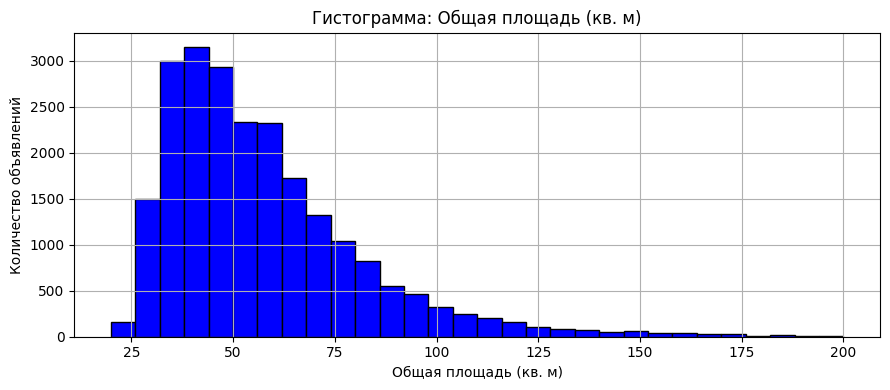

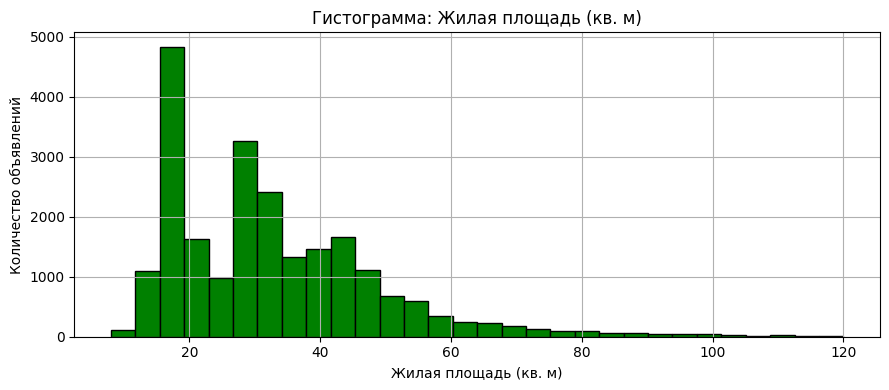

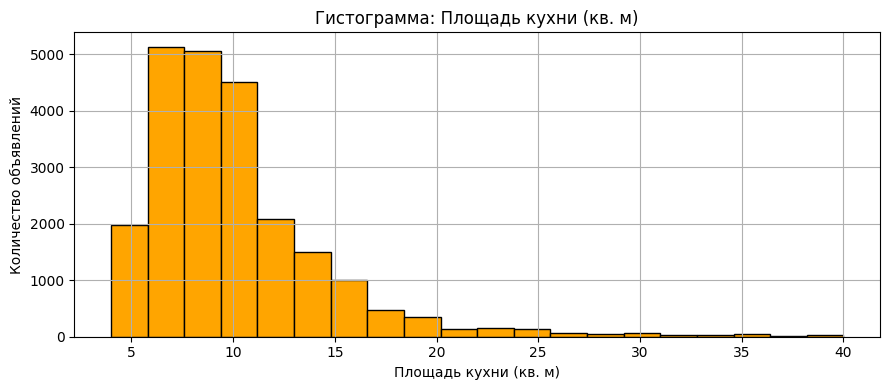

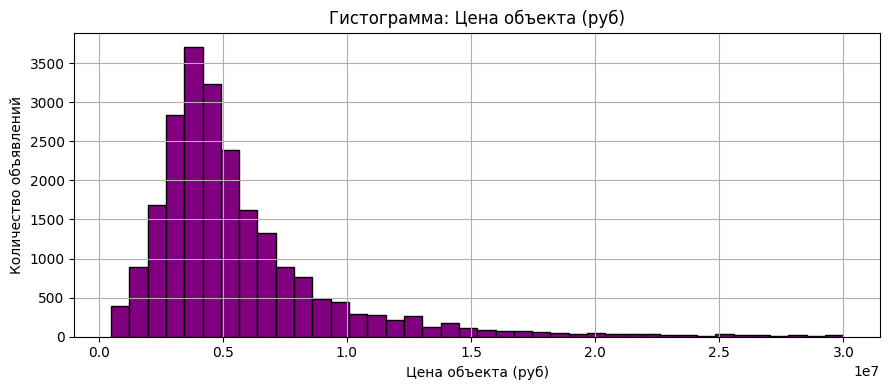

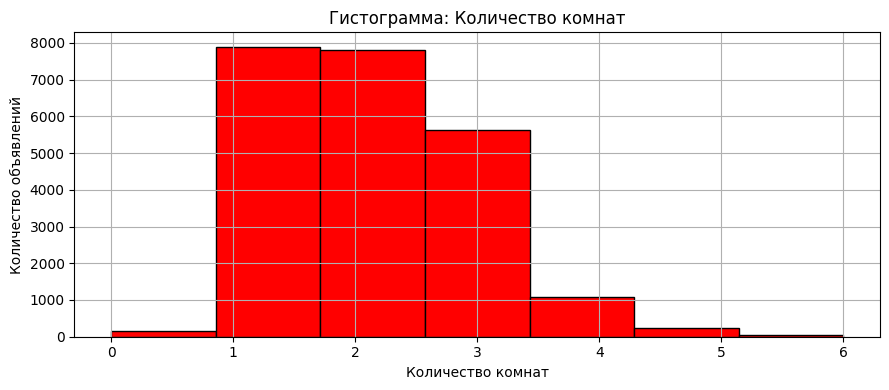

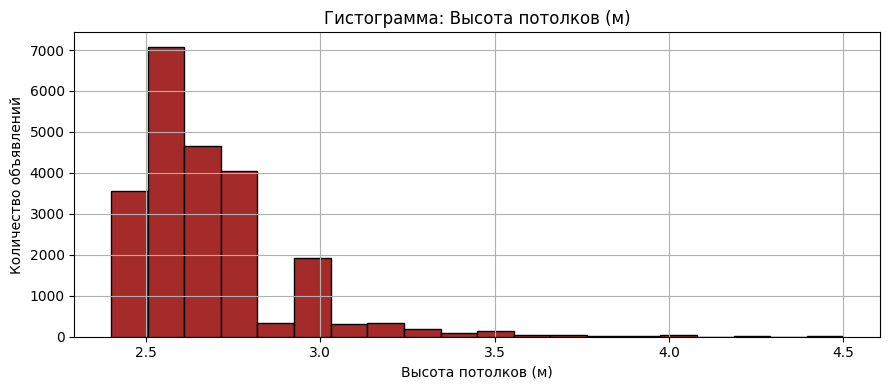

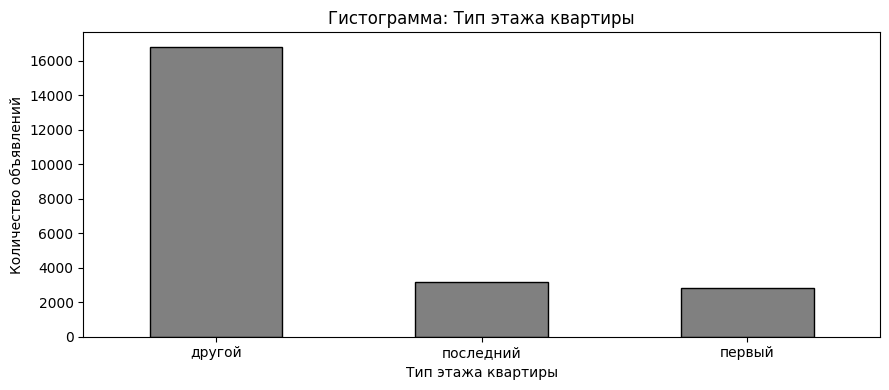

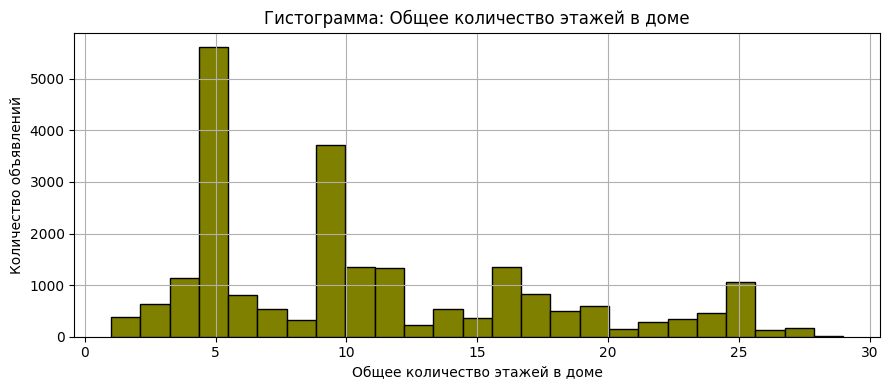

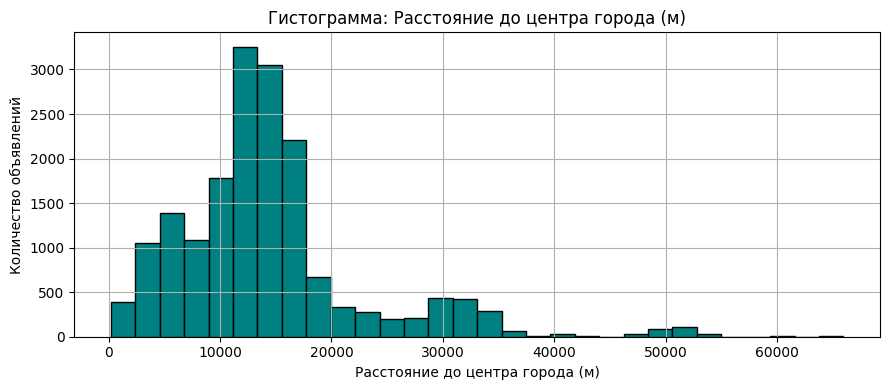

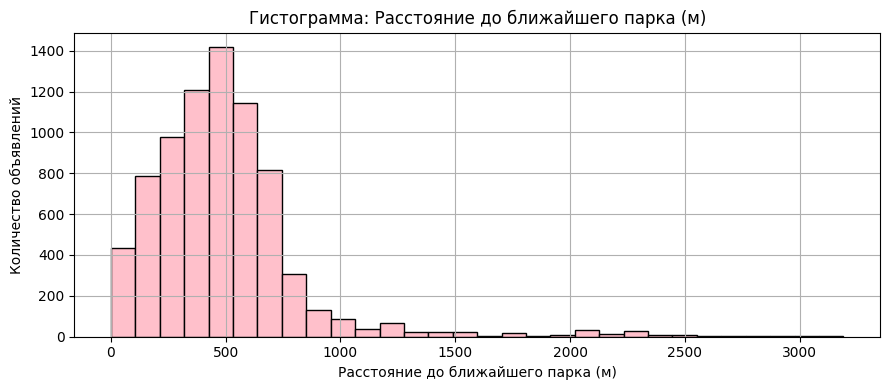

In [40]:
# Настройка списка параметров
params = [
    ("total_area", "Общая площадь (кв. м)", "blue", 30),
    ("living_area", "Жилая площадь (кв. м)", "green", 30),
    ("kitchen_area", "Площадь кухни (кв. м)", "orange", 20),
    ("last_price", "Цена объекта (руб)", "purple", 40),
    ("rooms", "Количество комнат", "red", 7),
    ("ceiling_height", "Высота потолков (м)", "brown", 20),
    ("floor_type", "Тип этажа квартиры", "gray", 3),
    ("floors_total", "Общее количество этажей в доме", "olive", 25),
    ("cityCenters_nearest", "Расстояние до центра города (м)", "teal", 30),
    ("parks_nearest", "Расстояние до ближайшего парка (м)", "pink", 30),
]

# Строим графики
for column, title, color, bins in params:
    plt.figure(figsize=(9, 4))

    if df_filtered[column].dtype == "object":
        # Для категориального параметра - столбчатая диаграмма частот
        df_filtered[column].value_counts().plot(kind="bar", color=color, edgecolor="black")
        plt.xticks(rotation=0)
    else:
        # Для числовых - классическая гистограмма
        df_filtered[column].hist(bins=bins, color=color, edgecolor="black", grid=True)

    plt.title(f"Гистограмма: {title}")
    plt.xlabel(title)
    plt.ylabel("Количество объявлений")
    plt.tight_layout()

#### Общая площадь
График общей площади достаточно плавный, вариативность размеров коридоров, кухонь, санузлов сглаживает границы между типами квартир:
* Самый популярный метраж в объявлениях сосредоточен в границах 35–45 кв.м (1-комнатные квартиры).
* Второй сильный подъем идет до 60 кв.м (соответствует метражу 2-комнатных, небольших 3-комнатных квартир).
* Жилье площадью более 100 кв.м формирует длинный пологий хвост распределения, занимая небольшую долю от общего объема рынка.

#### Жилая площадь
На графике видны несколько отстоящих пика:
* пик на отметке 18 кв.м: соответствует жилплощади однокомнатных квартир и просторных студий.
* пик на отметке 30 кв.м: типичная жилплощадь для двухкомнатных квартир массовых серий.
* пик около 42–45 кв.м: отражает жилплощадь 3-комнатных квартир.
* плавный спад после 50 кв. м показывает, что квартиры с огромными жилплощадями встречаются на рынке гораздо реже.

#### Цена объекта
График демонстрирует классическое асимметричное распределение с длинным «хвостом» вправо:
* самый высокий пик приходится на диапазон от 3.5 до 4.5 млн рублей. Это наиболее ликвидный и востребованный сегмент (однокомнатные квартиры/студии).
* большинство сделок укладывается в бюджет от 3 до 7 млн рублей.
* после отметки 10 млн рублей график идет на спад. Мы устанавливали порог на уровне 30 млн рублей, чтобы не смешивать массовый сегмент с дорогой элитной недвижимостью, хотя реалистичнее было бы еще больше снизить порог.

#### Количество комнат
График идеально иллюстрирует структуру предложения на рынке жилья: лидеры рынка 1 и 2-комнатные квартиры (их столбцы практически равны по высоте и находятся на пике - почти по 8 000 объявлений каждый); 3-комнатные оказались на втором месте - около 5 500 объявлений (семейный формат, покупают реже); студии (0 комнат) и многокомнатные (4–6 комнат) занимают минимальные доли рынка. Студии в этом датасете ещё являются редкостью (массовая застройка происходила чуть позже), а многокомнатные квартиры (4+) — это специфический и дорогой продукт (коммуналки или элитное жильё).

#### Высота потолков
Hынок поделен на три класса комфортности:
* Эконом/комфорт (основной пик 2.5–2.7 м) представляют подавляющее большинство - 2.5–2.55 м (хрущёвки, брежневки) и 2.6–2.7 м (современные панельные и монолитные дома стандарт-класса).
* Бизнес-класс и сталинки (пик на отметке 3.0 м) - изолированный заметный всплеск.
* Старый фонд и элитное жилье (плавный хвост от 3.2 до 4.5 м): квартиры с потолками выше 3.5 метров — исторический центр Санкт-Петербурга или современные премиальные пентхаусы.

#### Тип этажа квартиры
Наблюдаем распределение по законам математики и этажности зданий:
* категория «другой» (ок. 17 000 объявлений) доминирует. В любом доме выше 2 этажей средних этажей всегда физически больше, чем первого и последнего вместе взятых.
* объявлений на последнем этаже чуть больше, чем на первом. Квартиры на первом этаже традиционно считаются менее привлекательными из-за шума, близости к подвалам и отсутствия балконов, поэтому они активнее уходят в коммерческий фонд (под магазины/салоны).

#### Общее количество этажей в доме
Выделяются четыре пика:
* этажность «хрущевок» (пик на 5 этажах) отражает колоссальный объём пятиэтажной панельной и кирпичной застройки 1960–1970-х годов в регионе. Также хрущевки могут покупать в качестве первого недорогого жилья, а потом активно перепродавать.
* этажность «брежневок» и типовых панелей (пик на 9 этажах) - второй по величине всплеск. Массово строились в спальных районах с внедрением лифтов.
* позднесоветская этажность (пики на 12 и 16 этажах) отражают появление более высоких панельных серий и монолитных домов конца ХХ века.
* современная застройка (всплеск на 25 этажах) - черта новых высотных кварталов в спальных районах города и ближайшем пригороде (Кудрово, Мурино, Парнас, Шушары).

#### Расстояние до центра города
График имеет форму с несколькими вершинами (мультимодальное распределение).
* Исторический центр и прилегающие районы - небольшой пик в районе 5000 метров.
* Спальные районы - доминирующий пик в диапазоне от 11000 до 16000 метров. Зоны массовой советской и современной застройки (например, Приморский, Выборгский, Калининский или Фрунзенский районы), где сосредоточена основная часть городского жилья.
* Ближайший пригород - локальный всплеск в районе 30000 метров указывает на крупные города-спутники или обособленные районы (например, Колпино, Пушкин, Кронштадт, Петергоф).

#### Расстояние до ближайшего парка
Большинство объектов расположены в пешей доступности рядом с парками- основная масса значений сосредоточена в диапазоне от 200 до 700 метров с пиком 400-500м. Обычно наличие ухоженного парка рядом является хорошим фактором при продаже жилья (особенно для семей с детьми)

## Скорость продажи квартиры

In [41]:
# Расчет среднего и медианы (исключая пропуски, т.к. квартиры еще не проданы)
mean_days = df["days_exposition"].mean()
median_days = df["days_exposition"].median()

print(f"Среднее время продажи: {mean_days:.1f} дней")
print(f"Медианное время продажи: {median_days:.1f} дней")

Среднее время продажи: 180.7 дней
Медианное время продажи: 95.0 дней


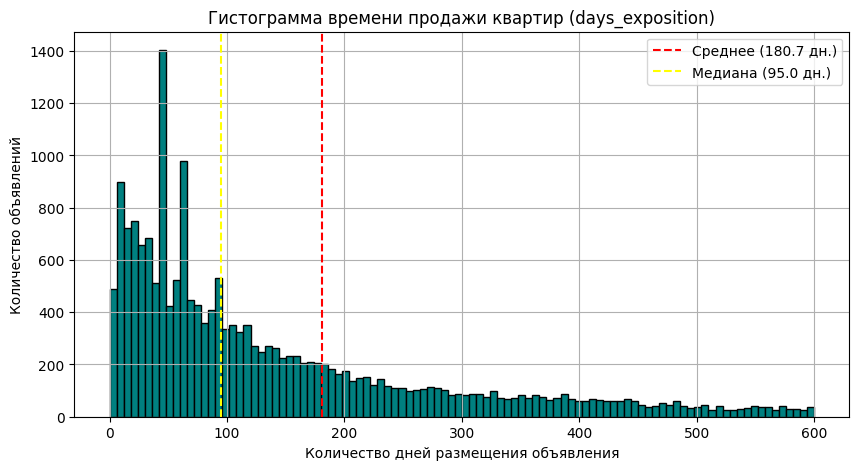

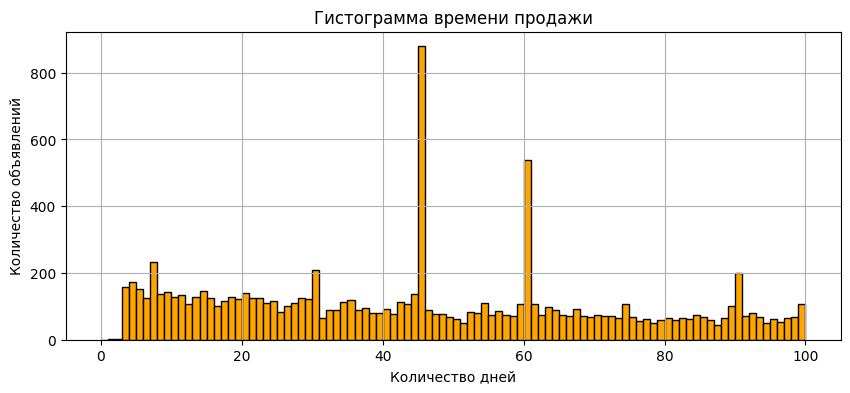

In [42]:
# Построение гистограммы (с ограничением до 600 дней)
plt.figure(figsize=(10, 5))
df["days_exposition"].hist(bins=100, range=(0, 600), color="teal", edgecolor="black")

# Добавление среднего и медианы
plt.axvline(mean_days, color="red", linestyle="--", label=f"Среднее ({mean_days:.1f} дн.)")
plt.axvline(median_days, color="yellow", linestyle="--", label=f"Медиана ({median_days:.1f} дн.)")

plt.title("Гистограмма времени продажи квартир (days_exposition)")
plt.xlabel("Количество дней размещения объявления")
plt.ylabel("Количество объявлений")
plt.legend()
plt.grid(True)

# Первые 100 дней
plt.figure(figsize=(10, 4))
df["days_exposition"].hist(bins=100, range=(0, 100), color="orange", edgecolor="black")
plt.title("Гистограмма времени продажи")
plt.xlabel("Количество дней")
plt.ylabel("Количество объявлений")
plt.grid(True)

### Анализ скорости продажи квартир
На основе `days_exposition` рассмотрели, сколько дней объявление оставалось активным на платформе до момента его закрытия.
* **Среднее время продажи:** ~180.7 дней (около 6 месяцев).
* **Медианное время продажи:** ~95 дней (около 3 месяцев).

среднее почти в два раза больше медианы, на рынке есть небольшой процент «зависших» объявлений, которые не продаются длительное время; но половина всех квартир продается быстрее чем за 3 месяца.

#### Скрытые особенности
При рассмотрении первых 100 дней на графике видны аномальные всплески («выбросы») на **45, 60 и 90 днях**. Это может быть техническиая особенность работы платформы Яндекс.Недвижимость. По истечении этих периодов система автоматически снимает бесплатные объявления с публикации, если продавец не продлил их вручную. Часть закрытий — автоматическое архивирование.

Опираясь на квантили распределения, можно составить шкалу успешности сделки:
- быстрые продажи (до 45 дней): если квартира уходит в первый месяц, это считается очень быстрой сделкой. На такие объекты нередко выставляют цену ниже рыночной; либо квартира обладает уникальными преимуществами, расположена в востребованной локации. Также сюда попадает часть автоматически снятых объявлений.
- обычные продажи (от 45 до 230 дней): срок от 1.5 до 7.5 месяцев позволяет продавцу найти покупателя, провести показы и одобрить ипотечную сделку.
- долгие продажи (свыше 230 дней): если квартира продается дольше 7–8 месяцев, то такая продажа затянулась. Свыше года (365 дней) — аномальный долгострой. Причинами долгих продаж может быть завышенная цена, плохая транспортная доступность, юридические проблемы с документами (обременения, доли), нежелание продавца идти на уступки или неликвидная планировка.

## Факторы влияния на стоимость

In [43]:
# Рассчет корреляции Пирсона
correlation_matrix = df_filtered[
    ["last_price", "total_area", "living_area", "kitchen_area", "rooms"]
].corr()
print(correlation_matrix["last_price"].sort_values(ascending=False))

last_price      1.000000
total_area      0.777168
living_area     0.672033
kitchen_area    0.609985
rooms           0.481618
Name: last_price, dtype: float64


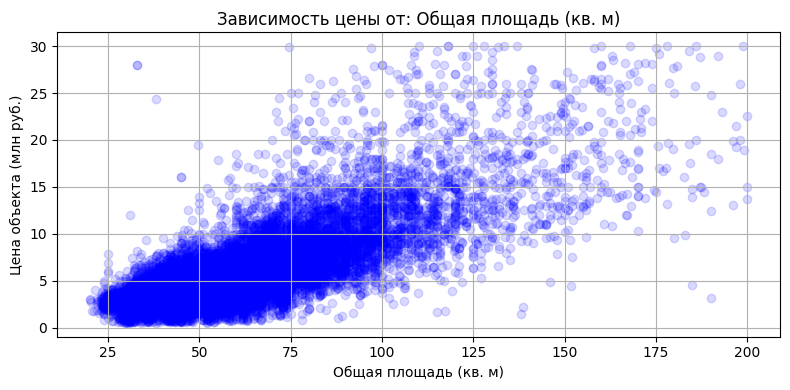

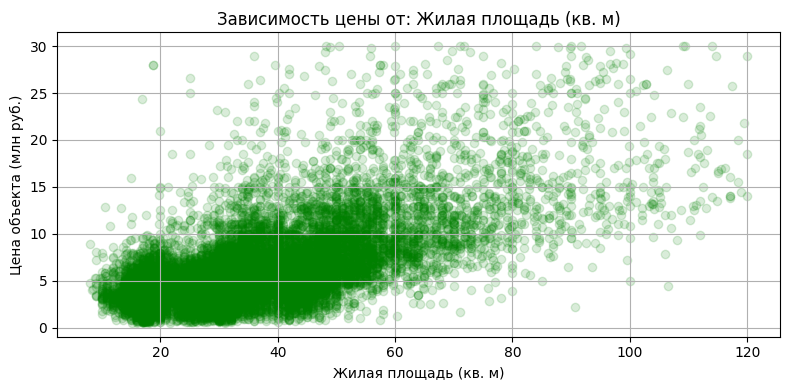

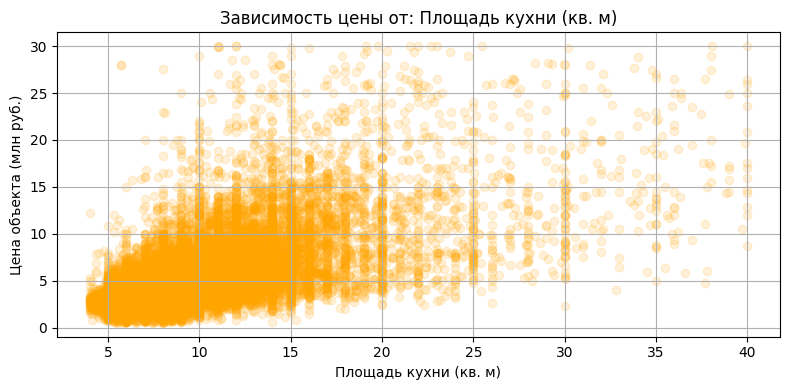

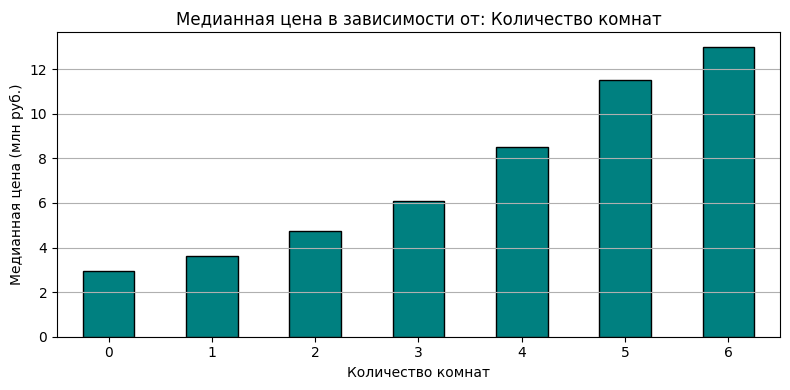

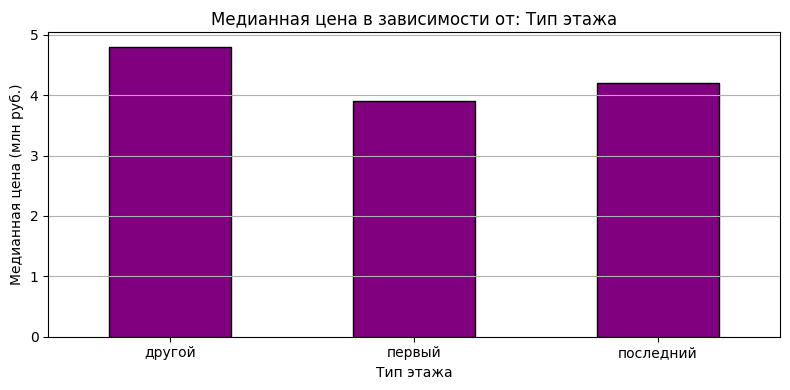

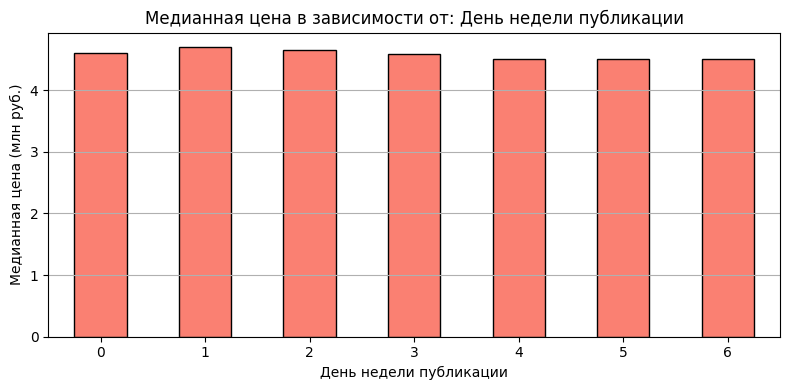

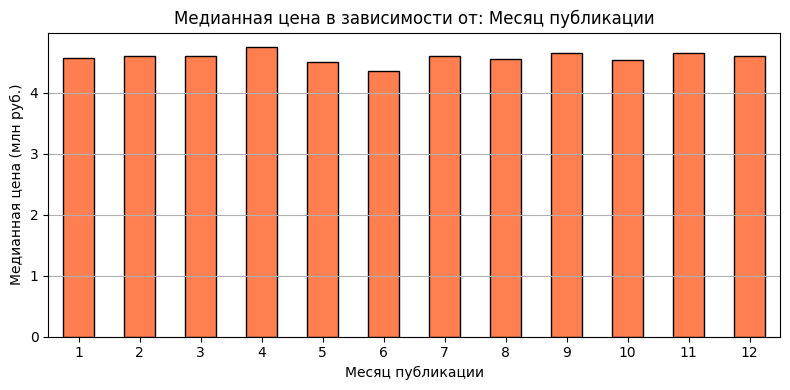

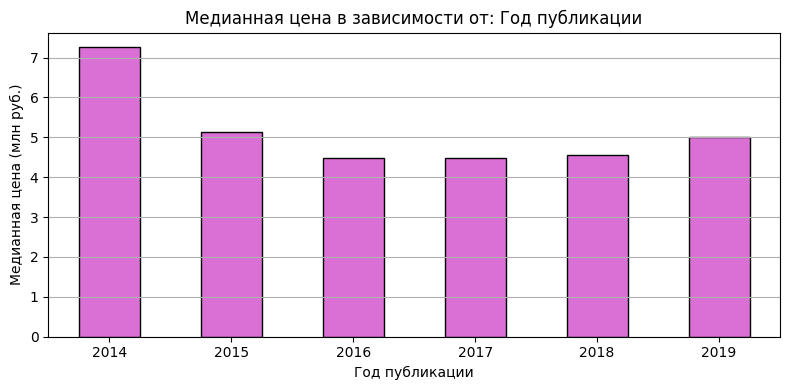

In [44]:
# Зависимость от площадей
area_params = [
    ("total_area", "Общая площадь (кв. м)", "blue"),
    ("living_area", "Жилая площадь (кв. м)", "green"),
    ("kitchen_area", "Площадь кухни (кв. м)", "orange"),
]

for col, title, color in area_params:
    plt.figure(figsize=(8, 4))
    # alpha для плотности распределения точек
    plt.scatter(
        df_filtered[col],
        df_filtered["last_price"] / 1000000,
        alpha=0.15,
        color=color,
    )
    plt.title(f"Зависимость цены от: {title}")
    plt.xlabel(title)
    plt.ylabel("Цена объекта (млн руб.)")
    plt.grid(True)
    plt.tight_layout()

# Функция для построения столбчатых графиков на основе медианной цены
categorical_params = [
    ("rooms", "Количество комнат", "teal"),
    ("floor_type", "Тип этажа", "purple"),
    ("weekday_exposition", "День недели публикации", "salmon"),
    ("month_exposition", "Месяц публикации", "coral"),
    ("year_exposition", "Год публикации", "orchid"),
]

for col, title, color in categorical_params:
    pivot = df_filtered.pivot_table(
        index=col, values="last_price", aggfunc="median"
    )
    # Переводим цену в миллионы для удобства чтения осей
    pivot["last_price"] = pivot["last_price"] / 1000000

    plt.figure(figsize=(8, 4))
    pivot["last_price"].plot(kind="bar", color=color, edgecolor="black")
    plt.title(f"Медианная цена в зависимости от: {title}")
    plt.xlabel(title)
    plt.ylabel("Медианная цена (млн руб.)")
    plt.xticks(rotation=0)
    plt.grid(axis="y")
    plt.tight_layout()

1. Влияние площадей (Диаграммы рассеяния)
- Общая площадь (total_area): облако точек имеет плотную, чётко направленную вверх форму. В диапазоне от 25 до 100 кв. м цена растёт предсказуемо и линейно. После 100 кв. м разброс цен увеличивается, так как начинают сильнее влиять другие факторы (локация и класс жилья). График демонстрирует сильную и стабильную прямую зависимость.
- Жилая площадь (living_area): связь с ценой прямая, но облако точек шире и имеет «размытую» структуру (особенно в районе 30–60 кв. м). При одинаковой жилой площади квартиры могут иметь разную общую площадь за счёт размеров кухни и коридоров.
- Площадь кухни (kitchen_area): при площади кухни от 5 до 15 кв. м наблюдается резкий вертикальный рост цен. Большая кухня — стандарт современного жилья комфорт/бизнес-класса, которое само по себе стоит значительно дороже старого фонда с 6-метровыми кухнями.

2. Дискретные параметры
- Количество комнат: наблюдается ступенчатый рост медианной стоимости с увеличением числа комнат. Студии (0 комнат) имеют медиану чуть меньше 3 млн руб., 1-комнатные квартиры — около 3.5 млн руб., а многокомнатные (5–6 комнат) уходят за отметку в 11–13 млн руб. Линейность графика подтверждает, что число комнат — один из главных ценообразующих факторов для покупателя.
- Тип этажа: подтверждается рыночное правило, что первый этаж — самый невостребованный и дешёвый (медианная цена ниже 4 млн руб.). Последний этаж ценится выше первого (около 4.2 млн руб.), но уступает промежуточным этажам (категория «другой»), медиана которых достигает почти 4.8 млн руб.

3. Факторы времени и сезонности
- День недели публикации: график практически идеально ровный. Выставление объявления во вторник (1) приносит незначительный пик цен, а в выходные (5 и 6) — едва заметный спад. День недели никак не влияет на реальную стоимость объекта.
- Месяц публикации: сезонные колебания цен минимальны, но тренд заметен. Самая низкая медианная цена зафиксирована в июне (6) — это разгар периода отпусков, наступление затишья. Локальный пик цен виден в апреле (4) — традиционный весенний всплеск деловой активности.
- Год публикации: график отражает макроэкономический кризис. В 2014 году медианная цена была максимальной (более 7 млн руб. — на рынке было много дорогого жилья). К 2016–2017 годам цены упали до минимума (около 4.5 млн руб.) из-за снижения покупательской способности. С 2018 по 2019 год наметился разворот тренда и стабильный рост рынка недвижимости.

Посчитаем среднюю цену одного квадратного метра в 10 населённых пунктах с наибольшим числом объявлений

In [47]:
# Построим сводную таблицу (количество объявлений и среднюю цену за кв. м)
locality_pivot = df_filtered.pivot_table(
    index="locality_name",
    values="price_per_meter",
    aggfunc=["count", "mean"],
)

# Переименуем столбцы
locality_pivot.columns = ["count_publications", "mean_price_per_meter"]

# Отберем 10 населённых пунктов с наибольшим числом объявлений
top10_localities = locality_pivot.sort_values(
    by="count_publications", ascending=False
).head(10)

# Округлим среднюю стоимость
top10_localities["mean_price_per_meter"] = (top10_localities["mean_price_per_meter"].round().astype(int))
print(top10_localities)

# Найдем населённые пункты с самой высокой и низкой стоимостью метра среди ТОП-10
most_expensive = top10_localities.sort_values(by="mean_price_per_meter", ascending=False).iloc[[0]]
most_cheapest = top10_localities.sort_values(by="mean_price_per_meter", ascending=False).iloc[[-1]]

print(f"\nСамая высокая стоимость метра: {most_expensive.index[0]} ({most_expensive['mean_price_per_meter'].values[0]} руб./кв.м)")
print(f"Самая низкая стоимость метра: {most_cheapest.index[0]} ({most_cheapest['mean_price_per_meter'].values[0]} руб./кв.m)")

                   count_publications  mean_price_per_meter
locality_name                                              
санкт-петербург                 15034                110432
поселок мурино                    534                 85238
поселок шушары                    434                 78276
всеволожск                        394                 68786
пушкин                            359                102856
колпино                           336                 75240
поселок парголово                 326                 90332
гатчина                           307                 68746
деревня кудрово                   294                 92298
выборг                            234                 58089

Самая высокая стоимость метра: санкт-петербург (110432 руб./кв.м)
Самая низкая стоимость метра: выборг (58089 руб./кв.m)


Сводная таблица позволила выделить топ-10 самых популярных локаций по количеству размещённых объявлений и сравнить среднюю стоимость квадратного метра в них.

*   **Лидер по стоимости - Санкт-Петербург** - Средняя цена квадратного метра = 110432. Ближе всего к показателям Петербурга подобрался город **Пушкин**, который высоко ценится за исторический статус, обилие парков и хорошую экологию.
    
*   **Самая низкая цена - Выборг** - Это может объясняться его значительной географической удалённостью от Санкт-Петербурга (более 120 км), из-за чего недвижимость там ориентирована строго на локальный внутренний рынок и не подходит для ежедневных поездок на работу в СПб. Второе место снизу делят между собой **Всеволожск** и **Гатчина**.

*   **Ситуация в ближайшем пригороде** - локации массовой современной застройки (**Мурино**, **Кудрово**, **Парголово**), удерживают прочные позиции в середине рейтинга. Стоимость метра в них ниже СПб, но существенно выше отдалённых городов области, т.к. эти районы интегрированы в транспортную и коммерческую сеть Санкт-Петербурга (наличие метро/близость к КАД).

## Анализ стоимости объектов в зависимсоти от удаленности от центра

([<matplotlib.axis.XTick at 0x79af66591a90>,
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12'),
  Text(13, 0, '13'),
  Text(14, 0, '14'),
  Text(15, 0, '15'),
  Text(16, 0, '16'),
  Text(17, 0, '17'),
  Text(18, 0, '18'),
  Text(19, 0, '19'),
  Text(20, 0, '20'),
  Text(21, 0, '21'),
  Text(22, 0, '22'),
  Text(23, 0, '23'),
  Text(24, 0, '24'),
  Text(25, 0, '25'),
  Text(26, 0, '26'),
  Text(27, 0, '27'),
  Text(28, 0, '28'),
  Text(29, 0, '29')])

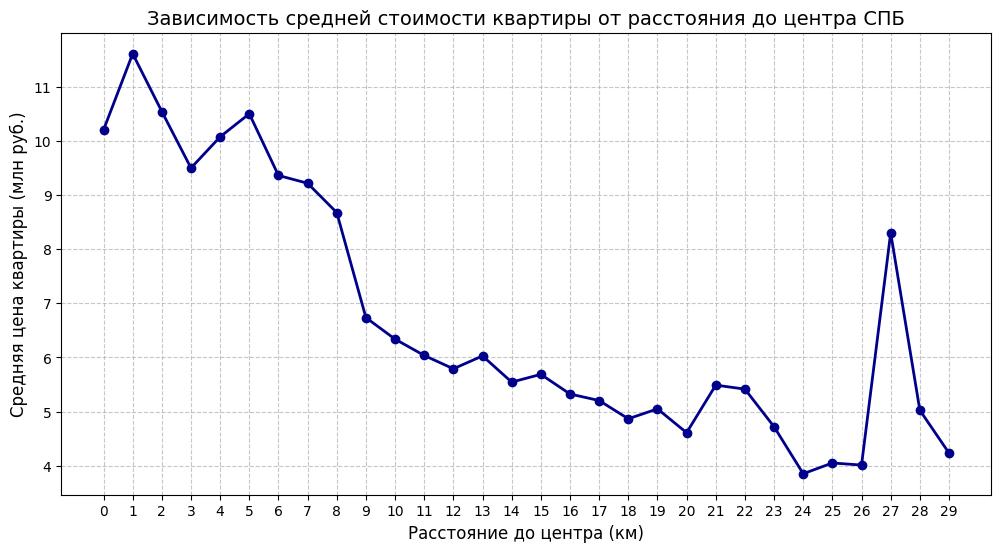

In [48]:
# Отбор квартиры строго в Санкт-Петербурге с данными о расстоянии
spb_flats = df_filtered[
    (df_filtered["locality_name"] == "санкт-петербург")
    & (df_filtered["cityCenters_nearest_km"].notna())
].copy()

# Сводная таблица - средняя цена для каждого километра удаленности
spb_spb_pivot = spb_flats.pivot_table(
    index="cityCenters_nearest_km", values="last_price", aggfunc="mean"
)

# Перевод цены в миллионы рублей
spb_spb_pivot["last_price_mln"] = spb_spb_pivot["last_price"] / 1000000

# Визуализация зависимости цены от километража
plt.figure(figsize=(12, 6))
plt.plot(
    spb_spb_pivot.index,
    spb_spb_pivot["last_price_mln"],
    marker="o",
    color="darkblue",
    linewidth=2,
    markersize=6,
)

plt.title(
    "Зависимость средней стоимости квартиры от расстояния до центра СПБ",
    fontsize=14,
)
plt.xlabel("Расстояние до центра (км)", fontsize=12)
plt.ylabel("Средняя цена квартиры (млн руб.)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)

# Шаг сетки по оси X через каждый 1 км
plt.xticks(range(0, int(spb_spb_pivot.index.max()) + 1, 1))

Действительно, на графике прослеживается некое ценовое зонирование:
- Зона центра (0–8 км): самые высокие цены на недвижимость. На отметках **1, 2 и 5 км** средняя стоимость квартир максимальна.
- При удалении от центра города к 9 километру цена стремительно и резко идет вниз. Любопытно, что на отметке 3км стоимость немного снижается.
- **Точка перелома:** На графике отчетливо виден сильный ценовой сдвиг в районе **8 км**, радиус центральной зоны Санкт-Петербурга составил 8 километров.
- Аномальный всплеск наблюдается на отметке 27 км, но если изучить карту, то на этой удаленности от центра расположен Пушкин и другие районы со своими преимуществами.
- В зоне между 9 и 26 км преобладают цены не выше 7 млн руб., что характерно для сегмента советских хрущевок

## Общий вывод
В ходе анализа были выявлены следующие тенденции:
1. Портрет типичного объекта недвижимости
- Самый массовый продукт на рынке — это 1/2-комнатная квартира общей площадью 35–45 кв. м, жилой площадью около 18 кв. м и кухней 6–11 кв. м.
- Стандартная высота потолков составляет 2.5–2.7 м, а сам объект чаще всего расположен в 5 или 9-этажном доме.
- Обычная сделка по продаже квартиры занимает около 3 месяцев (медиана — 95 дней). Продажи быстрее 45 дней считаются аномально быстрыми, а дольше 230 дней — необычно затяжными.
2. Главные ценообразующие факторы
- Площадь и комнаты: Общая площадь является одним из самых сильных факторов влияния на конечную цену объекта (корреляция Пирсона ~0.7). Количество комнат напрямую увеличивает общую стоимость, однако цена за квадратный метр при этом падает.
- Расположение этажа: медианная цена первых этажей самая низкая. Квартиры на последнем этаже стоят чуть дороже первого, но значительно уступают средним этажам.
- Сезонность и время: День недели и месяц публикации объявления практически не влияют на цену. В разрезе лет виден экономический тренд: падение рынка с 2014 по 2017 год и его стремительное восстановление и рост с 2018 по 2019 год.
3. География и влияние центра
- Рейтинг локаций: Самая высокая стоимость квадратного метра ожидаемо зафиксирована в Санкт-Петербурге (110 432 руб.) и историческом городе Пушкин (102 856 руб.). Самым дешёвым среди популярных мест оказался Выборг (58 089 руб.) из-за удалённости.
- Граница центра: радиус исторического центра Санкт-Петербурга составляет 8 км. В пределах этой зоны цены максимальны (пик на 1 км — 11.6 млн руб.), а на границе 8–9 км происходит резкий спад стоимости (падение на 2 млн руб. за километр). На расстоянии 27 км от центра обнаружен сильный ценовой всплеск (до 8.3 млн руб.), обусловленный наличием элитной недвижимости в престижном загородном Курортном районе (Сестрорецк, Репино) или Пушкине.